<a href="https://colab.research.google.com/github/KishorNaidu025/CodeAlpha_Iris_Flower_Classification/blob/main/CodeAlpha_Iris_Flower_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# CodeAlpha Internship - Project 1
# Iris Flower Classification

# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning libraries
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

# Display settings
pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:

# Load the Iris dataset
iris = load_iris()

# Convert dataset into a Pandas DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add target column
df['species'] = iris.target

# Display first five records
print("First five rows of the dataset:")
display(df.head())


First five rows of the dataset:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [ ]:

# Dataset information
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSpecies Distribution:")
print(df['species'].value_counts().sort_index())


Dataset Shape: (150, 5)

Column Names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'species']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB

Statistical Summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000



Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Species Distribution:
species
0    50
1    50
2    50
Name: count, dtype: int64


In [ ]:

# Convert numerical species labels into flower names

df['species_name'] = df['species'].map({
    0: 'Setosa',
    1: 'Versicolor',
    2: 'Virginica'
})

# Display the dataset
display(df.head())

# Count each flower species
print("\nSpecies Count:")
print(df['species_name'].value_counts())


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,species_name
0,5.1,3.5,1.4,0.2,0,Setosa
1,4.9,3.0,1.4,0.2,0,Setosa
2,4.7,3.2,1.3,0.2,0,Setosa
3,4.6,3.1,1.5,0.2,0,Setosa
4,5.0,3.6,1.4,0.2,0,Setosa



Species Count:
species_name
Setosa        50
Versicolor    50
Virginica     50
Name: count, dtype: int64


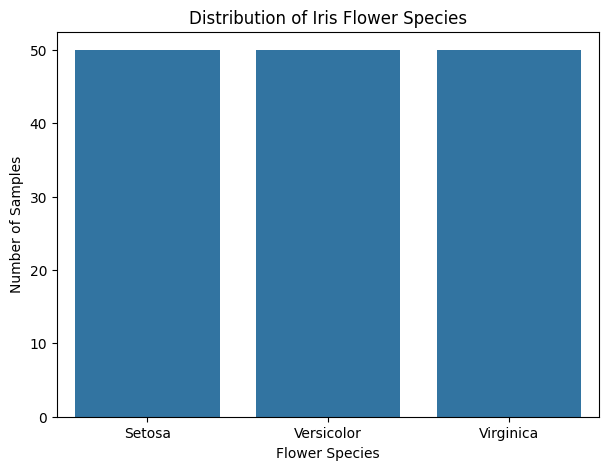

In [ ]:

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='species_name')

plt.title('Distribution of Iris Flower Species')
plt.xlabel('Flower Species')
plt.ylabel('Number of Samples')
plt.show()


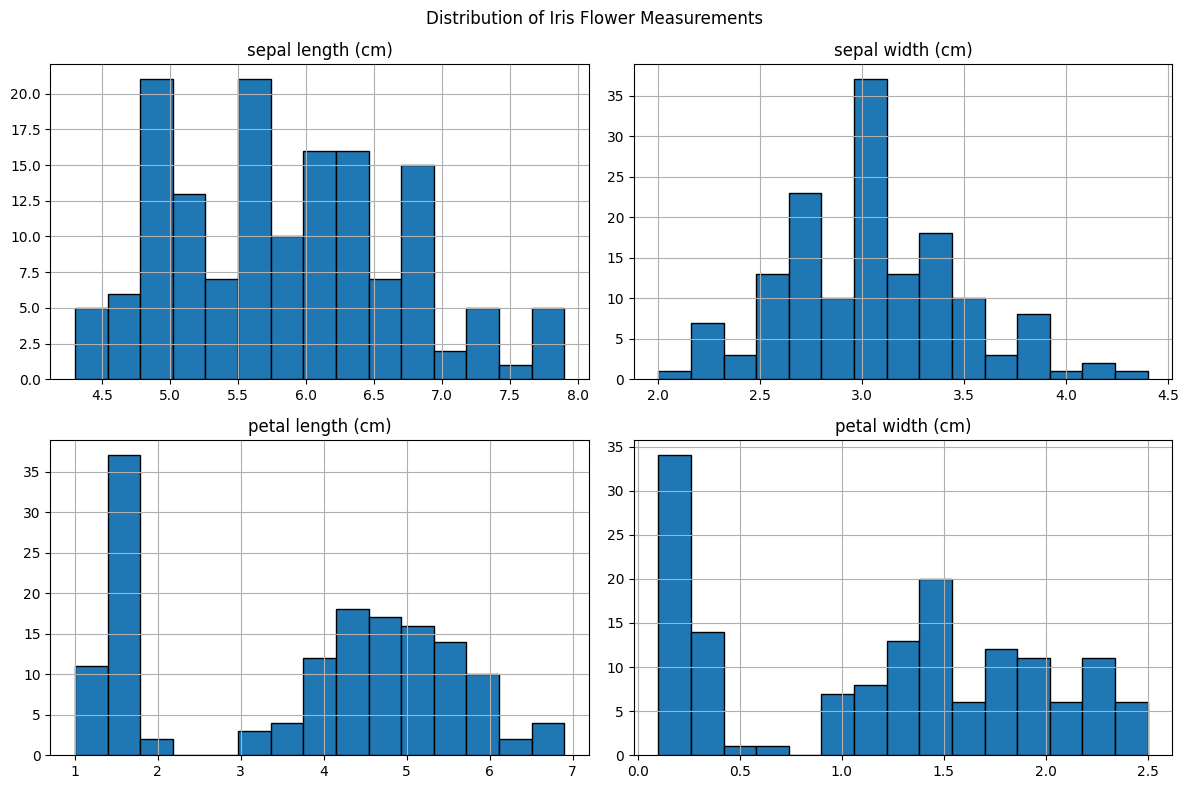

In [ ]:

# Create histograms for all four flower measurements

df[iris.feature_names].hist(
    figsize=(12, 8),
    bins=15,
    edgecolor='black'
)

plt.suptitle('Distribution of Iris Flower Measurements')
plt.tight_layout()
plt.show()


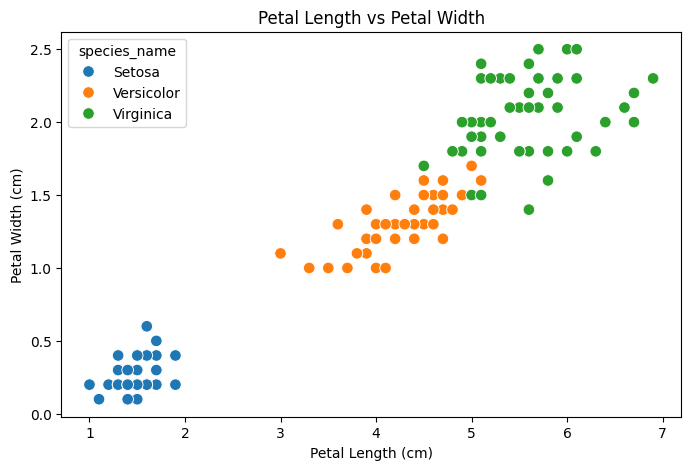

In [ ]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='petal length (cm)',
    y='petal width (cm)',
    hue='species_name',
    s=70
)

plt.title('Petal Length vs Petal Width')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Petal Width (cm)')
plt.show()


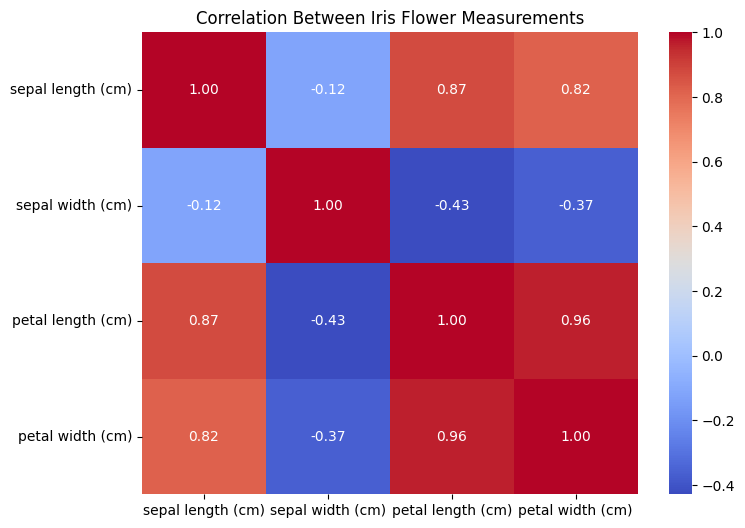

In [ ]:

plt.figure(figsize=(8, 6))

correlation = df[iris.feature_names].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Iris Flower Measurements')
plt.show()


In [ ]:

# Separate input features (X) and target variable (y)

X = df[iris.feature_names]
y = df['species']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)


Training data shape: (120, 4)
Testing data shape: (30, 4)
Training labels: (120,)
Testing labels: (30,)


In [ ]:
# Initialize and train the RandomForest model
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# Predict flower species
y_pred = model.predict(X_test)

# Display actual and predicted values
results = pd.DataFrame({
    'Actual Species': y_test.map({
        0: 'Setosa',
        1: 'Versicolor',
        2: 'Virginica'
    }),
    'Predicted Species': pd.Series(y_pred, index=y_test.index).map({
        0: 'Setosa',
        1: 'Versicolor',
        2: 'Virginica'
    })
})

display(results.head(10))

,Actual Species,Predicted Species
38,Setosa,Setosa
127,Virginica,Virginica
57,Versicolor,Versicolor
93,Versicolor,Versicolor
42,Setosa,Setosa
56,Versicolor,Versicolor
22,Setosa,Setosa
20,Setosa,Setosa
147,Virginica,Virginica
84,Versicolor,Versicolor


In [ ]:

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy: {:.2f}%".format(accuracy * 100))

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))


Model Accuracy: 90.00%

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



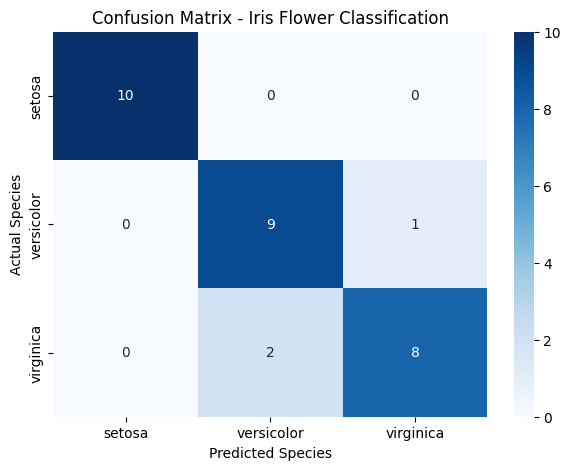

In [ ]:

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title('Confusion Matrix - Iris Flower Classification')
plt.xlabel('Predicted Species')
plt.ylabel('Actual Species')
plt.show()


In [ ]:

# New flower measurements:
# Sepal length, Sepal width, Petal length, Petal width

new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

prediction = model.predict(new_flower)

predicted_species = iris.target_names[prediction[0]]

print("New Flower Measurements:")
display(new_flower)

print("Predicted Flower Species:", predicted_species)


New Flower Measurements:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2


Predicted Flower Species: setosa
